# Week 3 - Classification Lesson

In [1]:
## 3.1. PROJECT OVERVIEW - PREDICT CUSTOMER CHURN AT A TELCOM COMPANY

## 3.2. DATA PREPARATION

In [2]:
# 3.1. IMPORT PACKAGES
import pandas as pd
import numpy  as np
import matplotlib.pyplot as plt

In [3]:
# 3.2 DOWNLOAD AND PREVIEW DATA
data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv'

df = pd.read_csv(data)
df.head()

# !wget $data -O data-week-3.csv


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# 3.3. STANDARDIZE COLUMN NAMES
# Preview column names
print(f"Column Names Before:\r\n {df.columns}")

# Standardize column names
df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = list(df.dtypes[df.dtypes == 'object'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

# Preview column names
print()
print(f"Column Names After:\r\n {df.columns}")

Column Names Before:
 Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

Column Names After:
 Index(['customerid', 'gender', 'seniorcitizen', 'partner', 'dependents',
       'tenure', 'phoneservice', 'multiplelines', 'internetservice',
       'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport',
       'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling',
       'paymentmethod', 'monthlycharges', 'totalcharges', 'churn'],
      dtype='str')


In [5]:
# 3.4 REVIEW pandas ASSIGNED COLUMN DATA TYPES
df.dtypes


customerid              str
gender                  str
seniorcitizen         int64
partner                 str
dependents              str
tenure                int64
phoneservice            str
multiplelines           str
internetservice         str
onlinesecurity          str
onlinebackup            str
deviceprotection        str
techsupport             str
streamingtv             str
streamingmovies         str
contract                str
paperlessbilling        str
paymentmethod           str
monthlycharges      float64
totalcharges            str
churn                   str
dtype: object

In [6]:
#   NOTE: THIS SHOULD THROW AN ERROR

# 'seniorcitizen' COLUMN HOLDS ONLY 1 AND 0 VALUES AS IF THIS IS A TRUE/FALSE VALUE
# WE CAN TREAT THIS AS A CATEGORICAL VALUE LATER

# 'totalcharges' WAS MISTYPED AS A STRING WHEN IT CLEARLY CONTAINS NUMERIC VALUES
# WE SHOULD CONVERT THIS TO A NUMERIC FIELD

# USE THE to_numeric() METHOD OF THE pandas PACKAGE TO CONVERT 'totalcharges' COLUMN 
# FROM STRING OBJECT TO NUMERIC
pd.to_numeric(df.totalcharges)

#   NOTE: THIS SHOULD THROW AN ERROR

ValueError: Unable to parse string " " at position 488

In [7]:
# THIS FAILED BECAUSE THERE WERE EMPTY SPACES IN THE RAW DATA IN THIS COLUMN
#  RECALL THAT WE REPLACED ALL SPACE CHARACTERS WITH UNDERSCORES, 
#  ERROR OCCURS BECAUSE 'pandas' IS UNABLE TO CONVERT AN UNDERSCORE TO A NUMBER

In [8]:
# CONVERT NUMERIC STRINGS TO NUMBERS - PART 1
#   STEP 1: USE THE 'errors='coerce' PARAMETER TO REPLACE CONVERSION ERRORS WITH 'NaN'
tc = pd.to_numeric(df.totalcharges, errors='coerce')

#   STEP 2: COUNT 'NaN' ERRORS
print(f"tc.isnull().sum()\t{tc.isnull().sum()}")

#   STEP 3: INSPECT 'NaN' records
#    df                              # Full dataframe
#    tc                              # dataframe of indices where the 'tc.isnull()' 
#                                    #  test returns a 'true'
#    ['customerid', 'totalcharges']  # List of columns to return from dataframe 'df'
df[tc.isnull()][['customerid', 'totalcharges']]

tc.isnull().sum()	11


,customerid,totalcharges
488,4472-LVYGI,
753,3115-CZMZD,
936,5709-LVOEQ,
1082,4367-NUYAO,
1340,1371-DWPAZ,
3331,7644-OMVMY,
3826,3213-VVOLG,
4380,2520-SGTTA,
5218,2923-ARZLG,
6670,4075-WKNIU,


In [9]:
# DEBUG
df[tc.isnull()][['customerid', 'totalcharges']]
# df['totalcharges']

,customerid,totalcharges
488,4472-LVYGI,
753,3115-CZMZD,
936,5709-LVOEQ,
1082,4367-NUYAO,
1340,1371-DWPAZ,
3331,7644-OMVMY,
3826,3213-VVOLG,
4380,2520-SGTTA,
5218,2923-ARZLG,
6670,4075-WKNIU,


In [10]:
# CONVERT NUMERIC STRINGS TO NUMBERS - PART 2
#  SINCE 'totalcharges' REPRESENTS CUSTOMERS WHO JUST JOINED, 
#  THE INITIAL BALANCE SHOULD BE ZERO
#    WE SHOULD REPLACE 'NaN' VALUES WITH ZEROS
#    THIS MAKES SENSE BECAUSE NEW CUSTOMERS HAVE NOT PAID ANYTHING YET
df.totalcharges = pd.to_numeric(df.totalcharges, errors='coerce')
df.totalcharges = df.totalcharges.fillna(0)

In [11]:
# PREVIEW 'churn' CATEGORICAL COLUMN CONTENTS
df.churn.head()

0     No
1     No
2    Yes
3     No
4    Yes
Name: churn, dtype: str

In [12]:
# CONVERT 'churn' CATEGORICAL VALUE
#  CONVERT 'yes' AND 'no' VALUES TO INTEGERS
#  df.churn column will be updated
#  where df.churn == 'Yes', update to '1', otherwise update to '0'
df.churn = (df.churn == 'Yes').astype(int)

In [13]:
# DEBUG
df.churn.head()

0    0
1    0
2    1
3    0
4    1
Name: churn, dtype: int64

## 3.3. VALIDATION

In [14]:
# IMPORT train-test-split FROM PACKAGE sklearn
from sklearn.model_selection import train_test_split

In [15]:
# SET ASIDE 20% FOR THE 'df_test' TEST DATASET
#   df_full_train    - name of dataset receive the bulk of the records taken from the full dataset
#   df_test          - name of remainder dataset to receive the remainder of the records from the full dataset
#   train_test_split - method within the 'model_selection' namespace of the 'sklearn' package
#   df               - dataframe containing all records
#   test_size        - percentage of full dataset to place into the remainder dataset
#   random_state     - seed for the random number generator
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)



In [16]:
# REPEAT THE PROCESS, BUT THIS TIME SPLIT THE 'df_full_train' INTO 'df_train' AND 'df_val'
#  SINCE WE WANT df_val TO CONTAIN 20% OF THE FULL 'df' DATASET, WE WILL NEED TO RECALCULATE
#  THE 'test_size' PARAMETER - 25% OF THE 'df_full_train' DATASET REPRESENTS 20% OF THE FULL 
#  'df' DATASET
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [17]:
# CONFIRM DATASET SIZES
print(f"length(df)             {len(df)}")
print()
print("\t----------------------------------")
print(f" \t| df_train | df_val\t| df_test")
print("\t----------------------------------")
print(f"\t| {len(df_train)} \t   | {len(df_val)} \t| {len(df_test)}")
print("\t----------------------------------")
print()
print(f"Sum of split datasets: {len(df_train) + len(df_val) + len(df_test)}")


length(df)             7043

	----------------------------------
 	| df_train | df_val	| df_test
	----------------------------------
	| 4225 	   | 1409 	| 1409
	----------------------------------

Sum of split datasets: 7043


In [18]:
# RESET INDEX VALUES FOR ALL SPLIT DATASETS
df_train = df_train.reset_index(drop=True)
df_val   = df_val.reset_index(drop=True)
df_test  = df_test.reset_index(drop=True)

In [19]:
# EXTRACT TARGET / LABEL FROM EACH DATASET
y_train  = df_train.churn.values
y_val    = df_val.churn.values
y_test   = df_test.churn.values

In [20]:
print(y_train.shape, y_val.shape, y_test.shape)

(4225,) (1409,) (1409,)


In [21]:
# NOW WE DELETE THE 'churn' COLUMNS FROM FEATURE DATASETS
#  ** DO NOT DELETE BEFORE TARGET / LABEL VECTORS HAVE BEEN CREATED **
del df_train['churn']
del df_val['churn']
del df_test['churn']

## 3.4. EDA

In [22]:
# reset index
df_full_train = df_full_train.reset_index(drop=True)

In [23]:
# DEBUG
df_full_train.shape

(5634, 21)

In [24]:
# Check all columns for missing values
df_full_train.isnull().sum()

customerid          0
gender              0
seniorcitizen       0
partner             0
dependents          0
tenure              0
phoneservice        0
multiplelines       0
internetservice     0
onlinesecurity      0
onlinebackup        0
deviceprotection    0
techsupport         0
streamingtv         0
streamingmovies     0
contract            0
paperlessbilling    0
paymentmethod       0
monthlycharges      0
totalcharges        0
churn               0
dtype: int64

In [25]:
# DEBUG
df_full_train.churn.value_counts(normalize=True)

churn
0    0.730032
1    0.269968
Name: proportion, dtype: float64

In [26]:
# look at the target variable - how many customers churned and how many stayed
df_full_train.churn.value_counts(normalize=True)

churn
0    0.730032
1    0.269968
Name: proportion, dtype: float64

In [27]:
print("  INTERPRETATION: About 73% of the customers stayed and 27% churned")

  INTERPRETATION: About 73% of the customers stayed and 27% churned


In [28]:
# Since 'churn' holds only binary data there is a shortcut for calculating the churn rate
#  We can use the .mean() function
#  with binary data, the function performs a sum of all values (1s and 0s), and divides by the total number of rows
df_full_train.churn.mean()

np.float64(0.26996805111821087)

In [29]:
# Decide which columns are hold categotical data
#  This can be done with a visual inspection of the data

# Create a list of columns containing numeric values
numerical = [
    'tenure', 
    'monthlycharges', 
    'totalcharges'
] 

# Create a list of columns containing categorical values
categorical = [
    'gender',
    'seniorcitizen',
    'partner',
    'dependents',
    'phoneservice',
    'multiplelines',
    'internetservice',
    'onlinesecurity',
    'onlinebackup',
    'deviceprotection',
    'techsupport',
    'streamingtv',
    'streamingmovies',
    'contract',
    'paperlessbilling',
    'paymentmethod',
]

# check number of unique values in each categorical column
df_full_train[categorical].nunique()

gender              2
seniorcitizen       2
partner             2
dependents          2
phoneservice        2
multiplelines       3
internetservice     3
onlinesecurity      3
onlinebackup        3
deviceprotection    3
techsupport         3
streamingtv         3
streamingmovies     3
contract            3
paperlessbilling    2
paymentmethod       4
dtype: int64

## 3.5. Risk

In [30]:
# Determining relevant features is part of EDA

# PART 1: Reference point
global_churn = df_full_train.churn.mean()

In [31]:
# PART 2: Review gender impact upon churn
churn_female = df_full_train[df_full_train.gender == 'female'].churn.mean()
churn_male   = df_full_train[df_full_train.gender == 'male'].churn.mean()

print(f"churn_female: {churn_female}")
print(f"churn_male:   {churn_male}")

churn_female: nan
churn_male:   nan


In [32]:
# Check to see how much of the global churn rate can be explained by female gender
global_churn - churn_female

np.float64(nan)

In [33]:
# Check to see how much of the global churn rate can be explained by male gender
global_churn - churn_male

np.float64(nan)

In [34]:
# INTERPRETATION: These factors have almost zero impact on global_churn, they are likely not important features

In [35]:
# PART 3: Review whether a customer has a partner impacts churn
df_full_train.partner.value_counts()

partner
No     2932
Yes    2702
Name: count, dtype: int64

In [36]:
churn_partner = df_full_train[df_full_train.partner == 'yes'].churn.mean()
churn_no_partner = df_full_train[df_full_train.partner == 'no'].churn.mean()

print(f"churn_partner:    {churn_partner}")
print(f"churn_no_partner: {churn_no_partner}")

churn_partner:    nan
churn_no_partner: nan


In [37]:
# # Check to see how much of the global churn rate can be explained by customer having a partner
global_churn - churn_partner     #  0.06493474245795922

np.float64(nan)

In [38]:
# # Check to see how much of the global churn rate can be explained by customer not having a partner
global_churn - churn_no_partner  # -0.05984095297455855

np.float64(nan)

In [39]:
# INTERPRETATION: 
#    Positive rate churns less than average
#    Negative rate churns more than average
#    The larger the absolute distance, the more significant the feature

In [40]:
# RISK RATIO
#
#    Risk_Ratio = Group_Risk / Global_Risk

In [41]:
from IPython.display import display

for c in categorical:
    print(c)
    df_group = df_full_train.groupby(c).churn.agg(['mean', 'count']) # Group by 'c' in 'categorical' list
                                                                     # then create new 'mean' and 'count' aggregate feature columns for 'churn'
    df_group['diff'] = df_group['mean'] - global_churn               # Add a 'diff' column
    df_group['risk'] = df_group['mean'] / global_churn               # Add a 'risk' column
    display(df_group)                                                # 'IPython' package method to display a table for each iteration of a loop
    print()
    print()
    

gender


,mean,count,diff,risk
gender,,,,
Female,0.276824,2796,0.006856,1.025396
Male,0.263214,2838,-0.006755,0.974980




seniorcitizen


,mean,count,diff,risk
seniorcitizen,,,,
0,0.242270,4722,-0.027698,0.897403
1,0.413377,912,0.143409,1.531208




partner


...

,mean,count,diff,risk
contract,,,,
Month-to-month,0.431701,3104,0.161733,1.599082
One year,0.120573,1186,-0.149395,0.446621
Two year,0.028274,1344,-0.241694,0.104730




paperlessbilling


,mean,count,diff,risk
paperlessbilling,,,,
No,0.172071,2313,-0.097897,0.637375
Yes,0.338151,3321,0.068183,1.252560




paymentmethod


,mean,count,diff,risk
paymentmethod,,,,
Bank transfer (automatic),0.168171,1219,-0.101797,0.622928
Credit card (automatic),0.164339,1217,-0.105630,0.608733
Electronic check,0.455890,1893,0.185922,1.688682
Mailed check,0.193870,1305,-0.076098,0.718121


print("INTERPRETATION")   \
print("  1. customers on a month-to-month contract churn far more than average, while two-year contracts almost never churn")   \
print("  2. fiber optic customers churn much more than DSL customers")   \
print("  3. customers paying by electronic check are the riskiest ")   \
print("")   \
print("CONCLUSION:")   \
print("  internet service and payment method look important; gender and phone service do not")   \

Notes   \
   \
Churn rate: Difference between global mean of the target variable and mean of the target variable for categories of a feature. If this difference is greater than 0, it means that the category is less likely to churn, and if the difference is lower than 0, the group is more likely to churn. The larger differences are indicators that a variable is more important than others.   \

Risk ratio: Ratio between mean of the target variable for categories of a feature and global mean of the target variable. If this ratio is greater than 1, the category is more likely to churn, and if the ratio is lower than 1, the category is less likely to churn. It expresses the feature importance in relative terms.   \
   \
Functions and methods:   \
   \
df.groupby('x').y.agg([mean()]) - returns a dataframe with mean of y series grouped by x series   \
display(x) displays an output in the cell of a jupyter notebook.   \

## MUTUAL THEORY (USE WITH CATEGORICAL DATA)  \
Mutual information is a concept from information theory. It tells us how much we can learn about one variable if we know the value of another.   \
   \
In concept, this means that if we have a Venn diagram with two partially overlapping circles and we understand one circle, then we know something about the elements of the second circle when they overlap with the first circle.  Therefore, understanding how much of the second circle overlaps with the first circle is important.  \


In [42]:
# Package 'sklearn' includes a function to calculate a mutual information score
from sklearn.metrics import mutual_info_score

In [43]:
# Measure the score for a the 'contract' feature column
#   Order of arguments does not matter
mutual_info_score(df_full_train.churn, df_full_train.contract)

0.0983203874041556

In [44]:
# Measure the score for a the 'gender' feature column
#   Order of arguments does not matter
mutual_info_score(df_full_train.gender, df_full_train.churn)

0.0001174846211139946

In [45]:
# Measure the score for a the 'partner' feature column
#   Order of arguments does not matter
mutual_info_score(df_full_train.partner, df_full_train.churn)

0.009967689095399745

### INTERPRETATION:   \
  1. The numbers confirm what we saw with the risk ratios.    \
  2. Contract has by far the highest score: knowing the contract type teaches us a lot about churn.    \
  3. Gender is almost 0: knowing the gender tells us practically nothing.    \
  4. Partner sits in between.   


In [46]:
## BETTER CODING APPROACH
#   This method automatically calculates the mutual info score for each categorical column/feature

# Declare a mutual_info_churn function
def mutual_info_churn_score(series):
    return mutual_info_score(series, df_full_train.churn)

# Apply 'mutual_info_churn_score' function to each column in the 'categorical' list
#   NOTE: '.apply() is a 'pandas' package function
mi = df_full_train[categorical].apply(mutual_info_churn_score)
mi.sort_values(ascending=False)

contract            0.098320
onlinesecurity      0.063085
techsupport         0.061032
internetservice     0.055868
onlinebackup        0.046923
deviceprotection    0.043453
paymentmethod       0.043210
streamingtv         0.031853
streamingmovies     0.031581
paperlessbilling    0.017589
dependents          0.012346
partner             0.009968
seniorcitizen       0.009410
multiplelines       0.000857
phoneservice        0.000229
gender              0.000117
dtype: float64

### Notes\
   \
Mutual information is a concept from information theory, which measures how much we can learn about one variable if we know the value of another. In this project, we can think of this as how much do we learn about churn if we have the information from a particular feature. So, it is a measure of the importance of a categorical variable.\
\
Classes, functions, and methods:\
\
mutual_info_score(x, y) - Scikit-Learn class for calculating the mutual information between the x target variable and y feature.\
df[x].apply(y) - apply a y function to the x series of the df dataframe.\
 df.sort_values(ascending=False).to_frame(name='x') - sort values in an ascending order and called the column as x.\



## 3.7. CORRELATION: (USE WITH NUMERIC VALUES)\
The **correlation coefficient** - the Pearson correlation coefficient, usually denoted r - measures the degree of dependency between two variables. It is always a number between -1 and 1:\
\
A value __close to 1 means strong positive correlation__:  when one variable grows, the other grows too.\
A value __close to -1 means strong negative correlation__: when one variable grows, the other decreases.\
A value __close to 0 means there is no dependency__:       a change in one variable tells us nothing about the other.\
The __sign gives the direction of the relationship__, and the _absolute value gives its strength_.\

One way to interpret the magnitude:\
\
**LOW** when the absolute value of r is between **0 and 0.2**\
**MEDIUM** when it is **between 0.2 and 0.5**\
**STRONG** when it is **between 0.5 and 1.0**\
\
If the correlation between a numerical feature and churn is positive, customers with **higher values of that feature churn more**; if it is negative, they churn less. The **larger the absolute value, the more important the feature**.\


In [47]:
# COMPUTE CORRELATION
#    'corrwith' is a 'pandas' function
#    'numerical' is a list of numerical columns/features
df_full_train[numerical].corrwith(df_full_train.churn)

tenure           -0.351885
monthlycharges    0.196805
totalcharges     -0.196353
dtype: float64

### INTERPRETATION: \
- **Tenure** has a medium negative correlation. The longer customers stay with the company, the less likely they are to churn. \
- **Monthly charges** have a low-to-medium positive correlation: the more customers pay per month, the more likely they are to churn. \
- **Total charges** have a low-to-medium negative correlation - not surprising, since total charges accumulate with tenure. \

In [48]:
# To rank importance of features, consider the absolute value of the difference
df_full_train[numerical].corrwith(df_full_train.churn).abs()

tenure            0.351885
monthlycharges    0.196805
totalcharges      0.196353
dtype: float64

### INTERPRETATION \
Tenure is the most important numerical feature.

In [49]:
# calculate 'tenure' value range (measured in months)
print(df_full_train.tenure.min())
print(df_full_train.tenure.max())

0
72


In [50]:
# break 'tenure' into 3 groups
# calculate mean for each group
# groups: 
#   1. less than 2 months
#   2. up to a year
#   3. more than a year

print(f"                x  <   2 months : {df_full_train[df_full_train.tenure <= 2].churn.mean()}")
print(f"  2 months  <=  x  <  12 months : {df_full_train[(df_full_train.tenure > 2) & (df_full_train.tenure <= 12)].churn.mean()}")
print(f" 12 months  <=  x               : {df_full_train[(df_full_train.tenure >= 12)].churn.mean()}")

                x  <   2 months : 0.5953420669577875
  2 months  <=  x  <  12 months : 0.3994413407821229
 12 months  <=  x               : 0.17986881937436933


### INTERPRETATION
The pattern is striking. Customers who have been with the company for two months or less churn at almost 60%. \
For customers of up to a year it is about 40%, and for \
those who stayed longer than a year only about 18%. \
\
Churn clearly decreases as tenure grows - exactly what the negative correlation told us.

In [51]:
# Perform same check for 'monthlycharges'
print(f"         x  <  $20 : {df_full_train[df_full_train.monthlycharges <= 20].churn.mean()}")
print(f" $20  <= x  <  $50 : {df_full_train[(df_full_train.monthlycharges > 20) & (df_full_train.monthlycharges <= 50)].churn.mean()}")
print(f" $50  <= x         : {df_full_train[(df_full_train.monthlycharges >= 50)].churn.mean()}")


         x  <  $20 : 0.08795411089866156
 $20  <= x  <  $50 : 0.18340943683409436
 $50  <= x         : 0.3248223216635957


### INTERPRETATION
Here the relationship goes the other way: customers paying at most $20 churn at about 9%,   \
and customers paying more than $50 churn at about 32%. \
The more people pay monthly, the more likely they are to leave - the positive correlation confirmed. \

## Notes 
\
Correlation coefficient measures the degree of dependency between two variables. This value is negative if one variable grows while the other decreases, and it is positive if both variables increase. Depending on its size, the dependency between both variables could be low, moderate, or strong. It allows measuring the importance of numerical variables. \
\
If r is correlation coefficient, then the correlation between two variables is: \
\
**LOW** when r is between [0, -0.2) or [0, 0.2) \
**MEDIUM** when r is between [-0.2, -0.5) or [0.2, 0.5) \
**STRONG** when r is between [-0.5, -1.0] or [0.5, 1.0] \
Positive Correlation vs. Negative Correlation \
\
When r is positive**, an increase in x will increase y. \
When r is negative**, an increase in x will decrease y. \
When r is 0, a change in x does not affect y. \
Functions and methods: \
\
df[x].corrwith(y) - returns the correlation between x and y series. This is a function from pandas. \


## OHE (ONE-HOT ENCODING)
One-hot encoding replaces one categorical column with several binary columns - one per category.

### 3.8. OHE (ONE-HOT ENCODING)
One-hot encoding replaces one categorical column with several binary columns - one per category. \
Only one of the created binary columns will store a '1' and all the others will store a '0' for each row \
The column with the '1' is called the 'hot' column \
 \
 'sklearn' has a function that automates the work of transforming a categorical feature into a collecton of one-hot columns.  This function requires the input data to be in a dictionary structure.

In [52]:
# CREATE THE TRAINING DATASET

# Import function used to apply one-hot encoding (OHE)
from sklearn.feature_extraction import DictVectorizer

# Create the 'dv' matrix 
dv = DictVectorizer(sparse=False) 

# Create the training dictionary
train_dict = df_train[categorical + numerical].to_dict(orient='records')

# Create training dataset with one0hot encoded columns
X_train = dv.fit_transform(train_dict)

In [53]:
# Create dictionary
#   orient='records' means that there will be one dictionary entry created for each dataframe row
dicts = df[categorical + numerical].to_dict(orient='records')

In [54]:
# BONUS: Preview 'dicts'
# dicts

In [55]:
# Like every Scikit-Learn transformer, it has a fit step and a transform step:
# 
#    'fit'            learns the list of categories for each column
#    'transform'      turns dictionaries into a matrix
#    'fit_transform'  does both in one call. 
# With 
#    'sparse=False'   the result is a usual NumPy array. 
#
# By default 'DictVectorizer' returns a sparse matrix 
#
# a SPARSE MATRIX is a data structure that stores only the non-zero elements, 
#   because most of the matrix is zeros. Sparse matrices are more memory efficient, 
#   but for this dataset it is simpler to work with a dense array.

In [56]:
# ENCODE THE VALIDATION DATASET

# Import function used to apply one-hot encoding (OHE)
from sklearn.feature_extraction import DictVectorizer

# Create the 'dv' matrix 
dv = DictVectorizer(sparse=False) 

# Create the training dictionary
train_dict = df_train[categorical + numerical].to_dict(orient='records')

# Create training dataset with one0hot encoded columns
X_train = dv.fit_transform(train_dict)

# preview training dataset
X_train.shape

(4225, 45)

In [57]:
# ENCODE THE VALIDATION DATASET
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

### Notes
\
One-Hot Encoding allows encoding categorical variables in numerical ones. This method represents each category of a variable as one column, and a 1 is assigned if the value belongs to the category or 0 otherwise. \
\
Classes, functions, and methods: \
\
df[x].to_dict(orient='records') - convert x series to dictionaries, oriented by rows. \
DictVectorizer().fit_transform(x) - Scikit-Learn class for one-hot encoding by converting x dictionaries into a sparse matrix. It does not affect the numerical variables. \
DictVectorizer().get_feature_names() - return the names of the columns in the sparse matrix. \

## 3.9. BINARY CLASSIFICATION \
Our problem - predicting churn - is a binary classification problem: \ 
1. the target variable takes one of two values.
2. We encoded it as 1 for customers who churned (the positive class) and 0 for customers who stayed (the negative class).
3. Spam detection is another example: 1 for spam, 0 for not spam.
\
A supervised model is a function that maps features to the target:\
\
g ( x i ) ≈ y i \
 \
For classification, the output of g is a number between 0 and 1: the probability that xi belongs to the positive class. \
If the model outputs 0.8 for a customer, we say it believes there is an 80% chance this customer will churn.\
\
\ ## LINEAR REGRESSION REFRESHER \
g ( x i ) = w0 + w1 X1 + w2 X2 + . . . + wn Xn \
\
## SIGMOID
g ( xi ) = Sigmoid( w0 + w1 x1 + w2 x2 + . . . + wn xn ) \
\
Logistic regression: the same weighted sum as in linear regression, passed through the sigmoid so the output lands between 0 and 1 instead of anywhere on the real line \
\
Sigmoid(z) = 1 / (1 + exp(−z) \
 \
 The sigmoid squashes any real number into the range between 0 and 1. That turns the raw score into a probability. Both models are called linear models, because the score inside is still a linear combination of the features - only the final transformation differs. 
 


In [58]:
import pandas as pd
import numpy  as np

import matplotlib.pyplot as plt

In [59]:
# numpy sigmoid
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [60]:
# Sanity check on sigmoid function
sigmoid(10000)    # should return 1.0

np.float64(1.0)

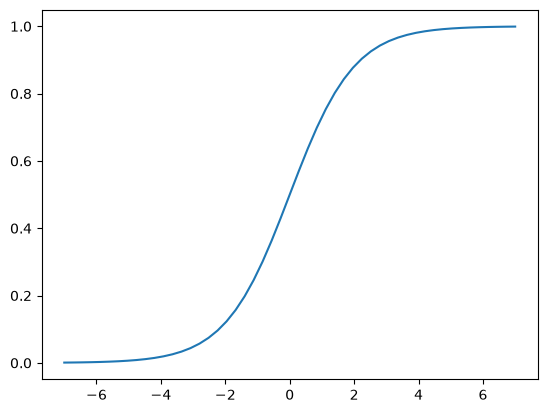

In [61]:
# A large positive score maps to 1.0. 
# A large negative score maps to 0, and 
# at exactly 0 the sigmoid gives 0.5 - a coin flip. 
# To see the shape, we evaluate the sigmoid on values from -7 to 7 and plot it

z = np.linspace(-7, 7, 51)
plt.plot(z, sigmoid(z))

# IMPLEMENTING THE SIGMOID MODEL

In [62]:
# REFRESHER: LINEAR REGRESSION FUNCTION RITTEN WITHOUT A LOOP

def linear_regression(xi):
    result = w0
    
    for j in range(len(w)):
        result = result + xi[j] * w[j]
        
    return result

The two functions are almost identical. \
This is the whole idea of this lesson: \ 
  **Logistic Regression is linear regression with a sigmoid on top**, \
  This which makes the output interpretable as a probability.

### SUMMARY 
**Notes**
 \
In general, supervised models can be represented with this formula: \
 \
g ( xi ) = y i  # "y subscript i" \
 \
Depending on what is the type of target variable, the supervised task can be regression or classification (binary or multiclass). Binary classification tasks can have negative (0) or positive (1) target values. The output of these models is the probability of x i belonging to the positive class. \
 \
Logistic regression is similar to linear regression because both models take into account the bias term and weighted sum of features. The difference between these models is that the output of linear regression is a real number, while logistic regression outputs a value between zero and one, applying the sigmoid function to the linear regression formula. \
 \
g ( xi ) = Sigmoid ( w0 + w1 x 1 + w2x2 + ... + wn xn ) \
    x subscript i \
    w subscript n \
    \
Sigmoid( z ) = 1 / (1 + exp( −z ) \
 \
In this way, the sigmoid function allows transforming a score into a probability.

## 3.10 LOGISTIC REGRESSION WITH Scikit-Learn
Training follows the same pattern as with LinearRegression \
1. create the model
2. fit the model with the feature matrix and target vector

In [73]:
# LOGISTIC REGRESSION NEEDS ONLY ONE CHANGE; 
#  PASS THE SCORE THRUGH THE SIGMOID FUNCTION BEFORE RETURNING IT

def logistic_regression(xi):
    score = w0
    
    for j in range(len(w)):
        score = score + xi[j] * w[j]
        
    result = sigmoid(score)
    return result

## 3.10 CLASSIFICATION

In [74]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(solver='lbfgs' , max_iter=10000)
# solver='lbfgs' is the default solver in newer version of sklearn
# for older versions, you need to specify it explicitly

# 'fit() method is used to train the model
model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",10000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use 

In [80]:
model.intercept_[0]

# LESSON SAYS THIS SHOULD RETURN
#  -0.10903395348323511

# IM RETURNING
#  np.float64(-0.046900430449174614)

np.float64(-0.046900430449174614)

In [81]:
# DEBUG - VALUES ARE ALL WRONG
model.coef_[0].round(3)

#  LESSON SAYS RETURN SHOULD BE
# array([ 0.475, -0.175, -0.408, -0.03 , -0.078,  0.063, -0.089, -0.081,
#       -0.034, -0.073, -0.335,  0.316, -0.089,  0.004, -0.258,  0.141,
#        0.009,  0.063, -0.089, -0.081,  0.266, -0.089, -0.284, -0.231,
#        0.124, -0.166,  0.058, -0.087, -0.032,  0.07 , -0.059,  0.141,
#       -0.249,  0.215, -0.12 , -0.089,  0.102, -0.071, -0.089,  0.052,
#        0.213, -0.089, -0.232, -0.07 ,  0.   

# I'M RETURNING
# array([ 0.683,  0.032, -0.679,  0.054, -0.018,  0.112, -0.159,  0.083,
#         0.037, -0.001, -0.494,  0.689, -0.159, -0.017, -0.189,  0.069,
#         0.156,  0.115, -0.159,  0.08 ,  0.282, -0.159, -0.088, -0.164,
#         0.2  , -0.046,  0.082, -0.054, -0.003,  0.105, -0.013,  0.069,
#        -0.033,  0.194, -0.095, -0.159,  0.289, -0.055, -0.159,  0.25 ,
#         0.232, -0.159, -0.037, -0.068,  0.   ])

array([ 0.683,  0.032, -0.679,  0.054, -0.018,  0.112, -0.159,  0.083,
        0.037, -0.001, -0.494,  0.689, -0.159, -0.017, -0.189,  0.069,
        0.156,  0.115, -0.159,  0.08 ,  0.282, -0.159, -0.088, -0.164,
        0.2  , -0.046,  0.082, -0.054, -0.003,  0.105, -0.013,  0.069,
       -0.033,  0.194, -0.095, -0.159,  0.289, -0.055, -0.159,  0.25 ,
        0.232, -0.159, -0.037, -0.068,  0.   ])

In [68]:
# MAKING PREDICTIONS
#  NOTE: 'predict_proba' returns a matrix with 2 columns
#           col 1   probability of class 0
#           col 2   probability of class 1
#         sum of the two columns always adds up to 1.0

# model.predict_proba(X_val)[:, 1]
y_pred = model.predict_proba(X_val)[:, 1]

In [69]:
# IF PROBABILITY OF CHURN IS 50% OR MORE

# y_pred >= 0.5
# np.where(y_pred == False, 0, 1)
# y_pred = np.where(y_pred == "False", 0, 1)
churn_decision = (y_pred >= 0.5)

In [70]:
# CHECK ACCURACY
(y_val == churn_decision).mean()

#  NOTE: Should be 0.8034066713981547

np.float64(0.8034066713981547)

In [71]:
# MAKE A PREDICTIONS DATAFRAME
df_pred = pd.DataFrame()
df_pred['probability'] = y_pred
df_pred['prediction'] = churn_decision.astype(int)
df_pred['actual'] = y_val

In [72]:
# MARK CORRECT PREDICTIONS
df_pred['correct'] = df_pred.prediction == df_pred.actual
df_pred.correct.mean()

#  NOTE: Should be 0.8034066713981547

np.float64(0.8034066713981547)

## Notes
This video was about training a logistic regression model with Scikit-Learn, applying it to the validation dataset, and calculating its accuracy. \
 

**Classes, functions, and methods:**
- <u>**`LogisticRegression().fit(X, y)`**</u> — trains the logistic regression model.
- <u>**`model.coef_[0]`**</u> — returns the model’s coefficients (weights).
- <u>**`model.intercept_[0]`**</u> — returns the model’s intercept (bias).
- <u>**`model.predict(X)`**</u> — predicts class labels for `X`.
- <u>**`model.predict_proba(X)`**</u> — returns the predicted probability for each class.



## 3.11. MODEL INTERPRETATION

### REFRESHER
* 'zip() is a core python function that joins two sequences together, element by element.

In [ ]:
a = [1, 2, 3, 4]
b = 'abcd'
dict(zip(a, b))